# Actividad práctico-experimental en el entorno académico

## Normalización y estandarización de datos médicos con CRISP-DM

![Logo del ITQ](img/ITQlogo.png)

| Campo | Información |
|---|---|
| **Cargo** | Docente Especialista |
| **Nombre del docente** | Ing. Elvis Pachacama Cabezas |
| **Asignatura** | Fundamentos de Machine Learning |
| **Carrera** | Inteligencia Artificial |
| **Estudiante** | Edgar Enrique Crespo Ch. |
| **Fecha** | 20-11-2026 |
| **Repositorio** |https://github.com/EdgarCrespo73/Fundamentos_de_machine_learning_ITQ/blob/main/Programa10EvaluacionRegresionLogistica_CRISP-DM.ipynb


# Fase 1. Comprensión del negocio 

> **Alcance y honestidad de este apartado.** Todo lo que se escribe aquí proviene de dos fuentes: (1) el contenido de este mismo notebook y (2) la documentación oficial del dataset incluida en scikit-learn (`datos.DESCR`). Lo que ninguna de las dos fuentes dice se marca como **«No especificado»**; no se asume ni se inventa.

## 1.1 Contexto


**Giro del negocio.** El notebook no describe una empresa real. El «negocio» es el análisis de datos médicos de pacientes con diabetes dentro de una práctica de aprendizaje automático supervisado.

## 1.2 Objetivo de negocio

El notebook no lo declara ,solo lo que carga y calcula. El dataset describe a 442 pacientes con diabetes y una *respuesta de interés*: «una medida cuantitativa de la progresión de la enfermedad un año después de la línea base»(DESCR).

> Objetivo de negocio (deducido): estimar esa medida de progresión de la enfermedad a partir de las características de cada paciente registradas en la línea base.

## 1.3 Objetivo de minería de datos

Según el código del notebook:

- Tipo de problema: regresión supervisada. La variable objetivo (`target`) es numérica continua.
- Algoritmo: SVR (*Support Vector Regression*) con C=10, gamma="scale", kernel="rbf", dentro de un Pipeline que antes aplica `StandardScaler`.
- **Estrategia de evaluación:** partición *holdout* 80 % entrenamiento / 20 % prueba (random_state=42) y validación cruzada KFold de 5 rondas sobre el conjunto de entrenamiento.
- **Métricas:** MAE, RMSE y MAPE.

## 1.4 Criterios de éxito

**No especificado.** El notebook no fija un umbral de error aceptable para MAE, RMSE ni MAPE. Solo mide y reporta las métricas.

## 1.5 Evaluación de la situación

| Elemento | Detalle |
|---|---|
| Recursos de software | Python, NumPy, pandas, Matplotlib, scikit-learn |
| Datos disponibles | `datasets.load_diabetes` de scikit-learn: viene incluido en la librería y no necesita archivos externos |
| Volumen | 442 registros (pacientes), 10 variables de entrada y 1 variable objetivo |
| Restricción conocida | Pocos registros: el *holdout* deja 353 para entrenar y 89 para probar |
| Restricción conocida | Las variables de entrada ya vienen centradas y escaladas (ver Fase 2), por lo que no se conocen sus unidades originales |
| Plazo, presupuesto, personal | **No especificado** |

## 1.6 Plan del proyecto (CRISP-DM aplicado a este notebook)

| Fase CRISP-DM | Dónde aparece | Estado |
|---|---|---|
| 1. Comprensión del negocio | Este apartado | Realizada |
| 2. Comprensión de los datos | Apartado siguiente | Realizada |
| 3. Preparación de los datos | Partición *holdout* y `StandardScaler` dentro del `Pipeline` | Código existente en el notebook (no se desarrolla aquí) |
| 4. Modelado | Definición del SVR | Código existente (no se desarrolla aquí) |
| 5. Evaluación | Validación cruzada, MAE/RMSE/MAPE y gráfico real vs. predicho | Código existente (no se desarrolla aquí) |
| 6. Despliegue | — | No incluido en el notebook |

# Fase 2. Comprensión de los datos (*Data Understanding*)

## 2.1 Recolección de los datos iniciales

Los datos no se leen de un archivo: se cargan con datasets.load_diabetes(as_frame=True). Según la documentación del dataset, su fuente es <https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html> y se usó en Efron, Hastie, Johnstone y Tibshirani (2004), *Least Angle Regression*, Annals of Statistics.

In [1]:
import numpy as np
from math import sqrt
from pprint import pprint
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, preprocessing
from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)
from sklearn.model_selection import (
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd
from sklearn.pipeline import Pipeline, make_pipeline


In [2]:

datos = datasets.load_diabetes(as_frame=True)
df = datos.frame

print("Dimensiones (filas, columnas):", df.shape)
display(df.head())

Dimensiones (filas, columnas): (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2.2 Descripción de los datos

Cada fila es un paciente. Las columnas y su significado, tal como los documenta DESCR:

| Columna | Significado (según `DESCR`) | Rol |
|---|---|---|
| `age` | Edad en años | Entrada |
| `sex` | Sexo | Entrada |
| `bmi` | Índice de masa corporal | Entrada |
| `bp` | Presión arterial promedio | Entrada |
| `s1` | `tc`: colesterol sérico total | Entrada |
| `s2` | `ldl`: lipoproteínas de baja densidad | Entrada |
| `s3` | `hdl`: lipoproteínas de alta densidad | Entrada |
| `s4` | `tch`: colesterol total / HDL | Entrada |
| `s5` | `ltg`: posiblemente el logaritmo del nivel de triglicéridos séricos | Entrada |
| `s6` | `glu`: nivel de azúcar en sangre | Entrada |
| `target` | Medida cuantitativa de la progresión de la enfermedad un año después de la línea base | **Objetivo** |

Lo que la documentación no dice: la codificación de `sex` (qué valor es hombre o mujer) y la unidad o escala de target.

Importante: DESCR indica que las 10 variables de entrada están *centradas en la media y escaladas por la desviación estándar multiplicada por √n_muestras* (la suma de cuadrados de cada columna es 1). Por eso age muestra valores como 0.038 y no una edad en años.

In [3]:
print("Tipos de dato:")
print(df.dtypes.value_counts().to_string(), "\n")
print("Valores nulos en total:    ", int(df.isna().sum().sum()))
print("Filas duplicadas:          ", int(df.duplicated().sum()))
print("Valores distintos en 'sex':", df["sex"].nunique(), "->", [round(float(v), 5) for v in sorted(df["sex"].unique())])
print("Valores distintos en 'target':", df["target"].nunique())

Tipos de dato:
float64    11 

Valores nulos en total:     0
Filas duplicadas:           0
Valores distintos en 'sex': 2 -> [-0.04464, 0.05068]
Valores distintos en 'target': 214


## 2.3 Exploración de los datos

### Estadísticos descriptivos

In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


### Variable objetivo (`target`)

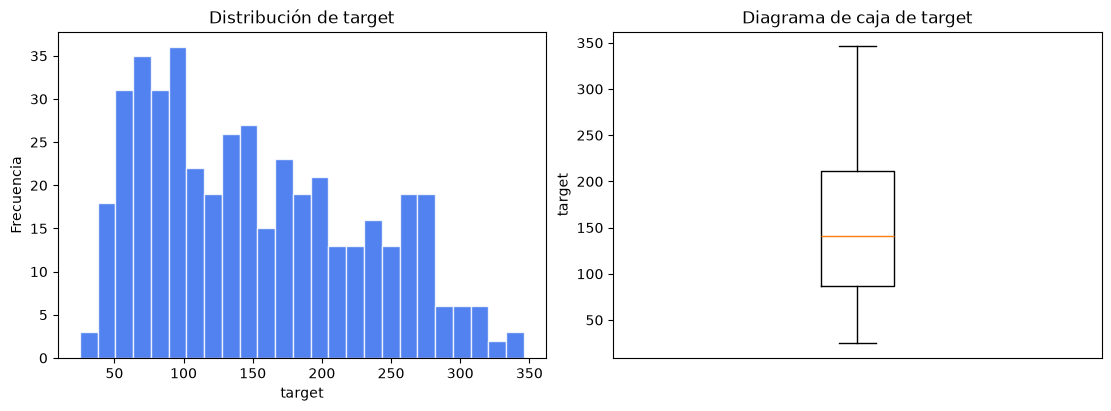

Asimetría (skew) de target: 0.441


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ejes[0].hist(df["target"], bins=25, color="#2563eb", alpha=0.8, edgecolor="white")
ejes[0].set(title="Distribución de target", xlabel="target", ylabel="Frecuencia")
ejes[1].boxplot(df["target"])
ejes[1].set(title="Diagrama de caja de target", ylabel="target", xticks=[])
plt.show()
print(f"Asimetría (skew) de target: {df['target'].skew():.3f}")

### Relación entre las variables de entrada

In [14]:
import numpy as np
corr_x = df.drop(columns="target").corr()
pares = (corr_x.abs()
         .where(np.triu(np.ones(corr_x.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False).head(5))
display(pares.round(3).to_frame("|Correlación|").rename_axis(["Variable A", "Variable B"]))

,,|Correlación|
Variable A,Variable B,
s1,s2,0.897
s3,s4,0.738
s2,s4,0.660
s4,s5,0.618
s1,s4,0.542


## 2.4 Verificación de la calidad de los datos

Se comprueba, con el código anterior y el siguiente, lo que la documentación afirma sobre el escalado.

In [15]:
X = df.drop(columns="target")
calidad = pd.DataFrame({
    "Media": X.mean(),
    "Suma de cuadrados": (X ** 2).sum(),
})
display(calidad.style.format({"Media": "{:.2e}", "Suma de cuadrados": "{:.4f}"}))

,Media,Suma de cuadrados
age,-1.44e-18,1.0000
sex,2.54e-18,1.0000
bmi,-2.26e-16,1.0000
bp,-4.85e-17,1.0000
s1,-1.43e-17,1.0000
s2,3.90e-17,1.0000
s3,-6.03e-18,1.0000
s4,-1.79e-17,1.0000
s5,9.17e-17,1.0000
s6,1.35e-17,1.0000


## 2.5 Hallazgos de la comprensión de los datos

**Estructura y calidad**
- El dataset tiene 442 filas y 11 columnas: 10 de entrada y target. Todas son numéricas (float64).
- **No hay valores nulos ni filas duplicadas**, por lo que no hace falta imputar ni eliminar registros.
- Las 10 variables de entrada tienen media = 0 y suma de cuadrados = 1, como indica la documentación. Ya están escaladas.
- sex toma solo 2 valores distintos (-0.0446 y 0.0507). Es una variable binaria cuya codificación original no está documentada.

**Variable objetivo**
- target va de 25 a 346, con media 152.13, mediana 140.5 y desviación estándar 77.09.
- Su asimetría es 0.44: ligeramente sesgada hacia valores altos.
- Tiene 214 valores distintos y ningún cero. Este último punto importa porque el MAPE divide entre el valor real.

**Relación entre variables de entrada**
- Hay pares fuertemente correlacionados: s1–s2 (0.897), s3–s4 (0.738) y s2–s4 (0.660). Existe redundancia entre las mediciones de colesterol.

**Implicación para el resto del notebook**
- Como las entradas ya vienen escaladas, el StandardScaler del Pipeline las vuelve a estandarizar. Esto no es un error, pero conviene saberlo al interpretar los resultados.
- `target` conserva su escala original, por eso MAE y RMSE se expresan en las unidades de target, que la documentación no precisa.

In [16]:
import numpy as np
from math import sqrt
from pprint import pprint
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, preprocessing
from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)
from sklearn.model_selection import (
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd
from sklearn.pipeline import Pipeline, make_pipeline



## Importar las librerías para la práctica de SVR

| Línea de código | Explicación |
|---|---|
| `import numpy as np` | Importa NumPy con el alias `np` para trabajar con arreglos y realizar operaciones numéricas. |
| `from math import sqrt` | Importa `sqrt()` para calcular raíces cuadradas. Por ejemplo, permite obtener el RMSE a partir del error cuadrático medio. |
| `from pprint import pprint` | Importa `pprint()` para imprimir estructuras como listas y diccionarios con un formato más legible. |
| `import matplotlib.pyplot as plt` | Importa `pyplot` con el alias `plt` para crear gráficos, por ejemplo, para comparar valores reales y predichos. |
| `import numpy as np` | Repite la primera importación de NumPy. Puedes eliminar esta segunda aparición. |
| `from sklearn import datasets, preprocessing` | Importa `datasets` para cargar conjuntos de datos como el de diabetes, y `preprocessing` para acceder a herramientas de transformación de datos. |
| `from sklearn.metrics import (` | Abre un bloque para importar varias funciones de métricas de scikit-learn, una por línea. |
| `make_scorer,` | Convierte una función de evaluación en un evaluador que puedes pasar a `cross_validate`. Para una métrica de error, puedes usar `greater_is_better=False` para indicar que un error menor es mejor. |
| `mean_absolute_error,` | Calcula el error absoluto medio (MAE). Es el promedio de las diferencias absolutas entre los valores reales y los predichos, en las mismas unidades de la variable objetivo. |
| `mean_absolute_percentage_error,` | Calcula el error porcentual absoluto medio (MAPE) y lo devuelve como proporción. Por ejemplo, `0.12` equivale a `12 %`. Si los valores reales están cerca de cero, el resultado puede ser muy grande. |
| `mean_squared_error,` | Calcula el error cuadrático medio (MSE). Eleva al cuadrado cada diferencia antes de promediarla, por lo que los errores grandes pesan más. |
| `)` | Cierra el bloque de importación de métricas. |
| `from sklearn.model_selection import (` | Abre un bloque para importar herramientas de división de datos y validación de modelos. |
| `KFold,` | Divide los datos en `k` grupos. En cada ronda se usa un grupo para validar y los demás para entrenar. |
| `cross_validate,` | Evalúa un modelo mediante validación cruzada y devuelve las puntuaciones de cada ronda para las métricas seleccionadas. |
| `train_test_split,` | Divide los datos en un conjunto de entrenamiento y otro de prueba. Si le pasas `X` e `y`, mantiene la correspondencia entre las filas y sus valores objetivo. |
| `)` | Cierra el bloque de importación de herramientas de validación. |
| `from sklearn import preprocessing` | Repite la importación del módulo `preprocessing`. Puedes eliminar esta línea porque ya se importó junto con `datasets`. |
| `from sklearn.preprocessing import StandardScaler` | Importa la clase `StandardScaler` para usarla directamente. Con su configuración predeterminada, resta la media de cada variable y la divide por su desviación estándar cuando esta es distinta de cero. Ajusta el escalador con los datos de entrenamiento y usa ese mismo ajuste para transformar los datos de prueba. |
| `from sklearn.base import clone## Cargar y explorar los datos` | Importa `clone()`, que crea una copia sin entrenar de un estimador con los mismos hiperparámetros. Desde el primer `#`, Python interpreta el resto como comentario. |



In [9]:
#Cargar y Explorar los Datos
datos = datasets.load_diabetes(as_frame = True)
#pprint(datos)
#pprint(np.shape,(datos.data))
df = datos.frame
display (df.head())
print("Dimensiones",df.shape)         

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dimensiones (442, 11)


## Cargar y explorar los datos

1. `#Cargar y Explorar los Datos`  
   Es un comentario que indica el propósito de la celda. Python ignora el texto que empieza con `#`.

2. `datos = datasets.load_diabetes(as_frame = True)`  
   Carga el conjunto de datos de diabetes de scikit-learn y guarda el resultado en `datos`. Con `as_frame=True`, las variables de entrada se pueden consultar como una tabla de pandas.

3. `#pprint(datos)`  
   Esta línea está comentada. Si quitas el `#`, `pprint()` muestra el contenido de `datos` con un formato más legible.

4. `#pprint(np.shape,(datos.data))`  
   Esta línea está comentada. Para consultar las dimensiones de las variables de entrada, usa `pprint(np.shape(datos.data))`. El resultado es `(442, 10)`, que corresponde a 442 filas y 10 columnas de entrada.

5. `df = datos.frame`  
   Guarda en `df` la tabla completa, que reúne las 10 variables de entrada y la columna `target` con los valores que el modelo aprenderá a predecir.

6. `display (df.head())`  
   `df.head()` selecciona las primeras cinco filas. `display()` las muestra como una tabla en el notebook.

7. `print("Dimensiones",df.shape)`  
   `df.shape` devuelve una tupla con el número de filas y columnas. La salida es `Dimensiones (442, 11)` porque la tabla completa incluye la columna `target`.

In [17]:
# Explorar la matriz de datos "X" y la variable objetivo "Y"
X = datos.data
Y = datos.target

## Separar las variables de entrada y la variable objetivo

1. `# Explorar la matriz de datos "X" y la variable objetivo "Y"`  
   Es un comentario que describe las variables que se van a usar. Las siguientes líneas las guardan por separado para poder explorarlas después.

2. `X = datos.data`  
   Guarda en `X` la tabla con las 10 variables de entrada de los 442 pacientes. Cada fila corresponde a un paciente y cada columna contiene una característica que el modelo usará para hacer predicciones. `X` tiene dimensiones `(442, 10)`.

3. `Y = datos.target`  
   Guarda en `Y` los 442 valores objetivo, uno por paciente. Cada valor es lo que el modelo SVR aprenderá a predecir a partir de las características de la fila correspondiente de `X`. Como `Y` es una serie de pandas, su forma es `(442,)`.

In [18]:
# Particion externa : Holdout split 80% train, 20% test.
X_train, X_test, y_train, y_test = train_test_split(X , Y, test_size = 0.20, random_state = 42)
print("Datos de entrenamiento", X_train.shape)
print("Datos de test", X_test.shape)

Datos de entrenamiento (353, 10)
Datos de test (89, 10)


## Partición externa de los datos (80 % entrenamiento y 20 % prueba)

1. # Particion externa : Holdout split 80% train, 20% test.  
   Es un comentario que describe la división *holdout*. Los datos se dividen una sola vez. Alrededor del 80 % se usa para entrenar el modelo y el 20 % se reserva para evaluarlo al final.

2. X_train, X_test, y_train, y_test = train_test_split(X , Y, test_size = 0.20, random_state = 42)  
   Divide `X` (las variables de entrada) e `Y` (la variable objetivo) manteniendo cada fila junto con su valor objetivo.
   - `X_train` e `y_train` contienen las entradas y los valores objetivo de entrenamiento.
   - `X_test` e `y_test` contienen las entradas y los valores objetivo de prueba.
   - `test_size = 0.20` reserva aproximadamente el 20 % de las filas para prueba.
   - `random_state = 42` fija la semilla para repetir la misma división al ejecutar la celda con los mismos datos.
     

3. print("Datos de entrenamiento", X_train.shape)  
   Muestra Datos de entrenamiento (353, 10). X_train tiene 353 filas y 10 columnas de entrada.

4. print("Datos de test", X_test.shape)  
   Muestra Datos de test (89, 10). X_test tiene 89 filas y las mismas 10 columnas de entrada.

In [22]:
# Métricas de evaluación.
metricas = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': make_scorer(lambda y, y_pred:
                        sqrt(mean_squared_error(y, y_pred)),
                        greater_is_better=False),
    'MAPE': make_scorer(lambda y, y_pred:
                        np.mean(np.abs((y - y_pred) / y)) * 100,
                        greater_is_better=False)}
    

## Métricas de evaluación del modelo SVR

1. `# Métricas de evaluación.`  
   Es un comentario que indica que esta celda define cómo se medirá el error de las predicciones.

2. `metricas = {`  
   Abre un diccionario llamado `metricas`. Cada clave identifica una métrica que se puede usar con `cross_validate(..., scoring=metricas)`.

3. `'MAE': 'neg_mean_absolute_error',`  
   Registra el **error absoluto medio (MAE)** de scikit-learn. Promedia las diferencias absolutas entre los valores reales y los predichos. Se expresa en las mismas unidades que la variable objetivo. El prefijo `neg_` indica que el resultado se devuelve con el signo invertido.

4. `'RMSE': make_scorer(lambda y, y_pred:`  
   Define el evaluador para la **raíz del error cuadrático medio (RMSE)**. La función `lambda` recibe los valores reales en `y` y las predicciones en `y_pred`.

5. `sqrt(mean_squared_error(y, y_pred)),`  
   Calcula el promedio de los errores al cuadrado y luego toma su raíz cuadrada. El RMSE queda en las mismas unidades que la variable objetivo y penaliza más los errores grandes que el MAE.

6. `greater_is_better=False),`  
   Indica que un RMSE menor es mejor. `make_scorer` invierte su signo para que una puntuación mayor represente un mejor resultado.

7. `'MAPE': make_scorer(lambda y, y_pred:`  
   Define el evaluador para el **error porcentual absoluto medio (MAPE)**. La función recibe los valores reales y los predichos.

8. `np.mean(np.abs((y - y_pred) / y)) * 100,`  
   Calcula el error relativo de cada predicción al dividir la diferencia por el valor real. `np.abs()` toma su valor absoluto, `np.mean()` calcula el promedio y `* 100` lo convierte a porcentaje. Si un valor real es cero, esta fórmula produce una división por cero.

9. `greater_is_better=False)}`  
   Indica que un MAPE menor es mejor y que el evaluador devuelve el porcentaje con el signo invertido. `)` cierra `make_scorer` y `}` cierra el diccionario.

**Cómo leer los resultados.** Multiplica las puntuaciones de estas tres métricas por `-1` para recuperar los errores. Por ejemplo, una puntuación MAPE de `-25` representa un error porcentual absoluto medio de **25 %**.

In [14]:
from sklearn.svm import SVR

# Escalador: aprende la media y la desviación estándar con los datos de entrenamiento
standarizer = StandardScaler()

# Definimos un algoritmo SVM de regresión
alg = Pipeline([
    ("standarizer", standarizer),
    ("regresion", SVR(C=10, gamma="scale", kernel="rbf")),
])

## Definir el modelo de regresión SVR


1. `standarizer = StandardScaler()`  1
   Crea un escalador. Cuando se ajuste el pipeline, el escalador aprenderá la media y la desviación estándar de cada columna a partir de los datos de entrenamiento.

2. `# Definimos un algoritmo SVM de regresión`  
   Es un comentario que describe el propósito del bloque.

3. `alg = Pipeline([`  
   Empieza a construir el pipeline y lo asigna a `alg`. Los pasos se ejecutan en el orden en que aparecen en la lista.

4. `("standarizer", standarizer),`  
   Añade el escalado como primer paso. `"standarizer"` es el nombre del paso y `standarizer` es el objeto que transforma las variables de entrada.

5. `("regresion", SVR(C=10, gamma="scale", kernel="rbf")),`  
   Añade la regresión SVR como segundo paso. El modelo recibe las variables ya escaladas.
   - `C=10` controla cuánto se penalizan los errores que superan el margen de tolerancia del SVR.
   - `gamma="scale"` calcula automáticamente el valor de `gamma` a partir del número de variables y la varianza de los datos que recibe el SVR. `gamma` controla qué tan local es la influencia de cada punto.
   - `kernel="rbf"` usa una función de base radial, que permite al modelo aprender relaciones no lineales.

6. `])`  
   Cierra la lista de pasos y la llamada a `Pipeline`. En este punto el modelo queda configurado. El entrenamiento ocurre al llamar a `alg.fit(X_train, y_train)` o al usar `alg` en la validación cruzada.

In [15]:
# Validación cruzada con los datos de entrenamiento
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = cross_validate(alg, X_train, y_train, cv=cv, scoring=metricas)

# Tabla de validación cruzada
tabla_cv = pd.DataFrame({
    "MAE": -results["test_MAE"],
    "RMSE": -results["test_RMSE"],
    "MAPE": -results["test_MAPE"],
})
tabla_cv.index = [f"Ronda {i}" for i in range(1, len(tabla_cv) + 1)]
tabla_cv.loc["Promedio"] = tabla_cv.mean()

display(
    tabla_cv.style
    .set_caption("Validación cruzada · 5 rondas")
    .format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE": "{:.2f} %"})
    .set_properties(
        subset=pd.IndexSlice[["Promedio"], :],
        **{"background-color": "#e8f1fb", "color": "#17365d", "font-weight": "bold"},
    )
)

# Entrenamiento final y evaluación en el conjunto de prueba
model = clone(alg)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

tabla_test = pd.DataFrame({"MAE": [mae]}, index=["Conjunto de prueba"])
display(
    tabla_test.style
    .set_caption("Evaluación final")
    .format("{:.2f}")
)

,MAE,RMSE,MAPE
Ronda 1,48.26,57.68,32.83 %
Ronda 2,51.99,60.27,45.90 %
Ronda 3,42.20,51.95,37.75 %
Ronda 4,45.73,55.51,43.12 %
Ronda 5,50.40,63.98,44.17 %
Promedio,47.72,57.88,40.75 %


,MAE
Conjunto de prueba,41.32


## Validación cruzada y evaluación final del SVR

### Validación cruzada

1. `import pandas as pd` importa pandas para construir y dar formato a las tablas.
2. `cv = KFold(n_splits=5, shuffle=True, random_state=42)` mezcla los datos de entrenamiento y los divide en cinco grupos reproducibles. En cada ronda se entrena con cuatro grupos y se valida con el restante.
3. `results = cross_validate(alg, X_train, y_train, cv=cv, scoring=metricas)` evalúa el pipeline con las métricas definidas y guarda las puntuaciones de cada ronda.

### Presentación de los resultados

4. `tabla_cv = pd.DataFrame({...})` crea una tabla con una fila por ronda. Cada línea del diccionario añade una columna.
   - `"MAE": -results["test_MAE"]` recupera el error absoluto medio de cada ronda.
   - `"RMSE": -results["test_RMSE"]` recupera la raíz del error cuadrático medio.
   - `"MAPE": -results["test_MAPE"]` recupera el error porcentual absoluto medio. Tu métrica ya lo calculó como porcentaje.
   
   El signo `-` revierte el signo que scikit-learn usa para presentar estas métricas como puntuaciones.
5. `tabla_cv.index = [...]` asigna las etiquetas **Ronda 1** a **Ronda 5**.
6. `tabla_cv.loc["Promedio"] = tabla_cv.mean()` añade una fila con el promedio de cada columna.
7. `display(...)` muestra la tabla en Jupyter. `.style` permite darle formato, `.set_caption(...)` agrega el título y `.format(...)` muestra dos decimales. `.set_properties(...)` usa `pd.IndexSlice` para aplicar color y negrita a las celdas de la fila **Promedio**.

### Evaluación en el conjunto de prueba

8. `model = clone(alg)` crea una copia sin entrenar del pipeline evaluado.
9. `model.fit(X_train, y_train)` ajusta el escalador y entrena el SVR con todos los datos de entrenamiento.
10. `y_pred = model.predict(X_test)` genera una predicción para cada fila de prueba.
11. `mae = mean_absolute_error(y_test, y_pred)` calcula cuánto se apartan, en promedio y en valor absoluto, las predicciones de los valores reales.
12. `tabla_test = pd.DataFrame(...)` coloca el MAE final en una tabla de una fila.
13. `display(...)` muestra la tabla final con el título **Evaluación final** y el MAE con dos decimales.

In [16]:
# Una vez hemos optimizado los hiperparámetros en el conjunto de validación, entrenamos un nuevo modelo que contenga
# todos los datos de entrenamiento (es decir, train + validation) para evaluar el test
#model = SVR(C=10, gamma='scale', kernel='rbf')
model = clone(alg)
model = model.fit(X_train, y_train)

## Entrenamiento final y evaluación del SVR

### Celda 1 · Entrenamiento

1. `# Una vez hemos optimizado los hiperparámetros en el conjunto de validación, entrenamos un nuevo modelo que contenga`  
   Introduce el entrenamiento final con la configuración elegida. En esta práctica, `cross_validate` evaluó los hiperparámetros que ya habías fijado en `alg`.

2. `# todos los datos de entrenamiento (es decir, train + validation) para evaluar el test`  
   Indica que el modelo final se ajusta con todo `X_train`, incluidas las filas que sirvieron para validar en alguna ronda de `KFold`. `X_test` queda reservado para la evaluación final.

3. `#model = SVR(C=10, gamma='scale', kernel='rbf')`  
   Es una línea comentada. Si se activara, crearía un SVR directamente con esos tres hiperparámetros.

4. `model = clone(alg)`  
   Crea una copia sin entrenar del pipeline `alg`, con el escalador y la misma configuración del SVR que evaluaste.

5. `model = model.fit(X_train, y_train)`  
   Ajusta el escalador con `X_train`, transforma las variables de entrada y entrena el SVR con ellas y con los valores objetivo de `y_train`. `fit()` devuelve el pipeline ajustado.



In [17]:
# Extraemos el error absoluto promedio (MAE) del conjunto de test
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print('Test results (MAE): ', mae)

Test results (MAE):  41.31967129510745


## Evaluacion

1. `# Extraemos el error absoluto promedio (MAE) del conjunto de test`  
   Indica que esta celda mide el error sobre los datos de prueba.

2. `y_pred = model.predict(X_test)`  
   Aplica a `X_test` el escalado aprendido durante el entrenamiento y genera una predicción para cada fila.

3. `mae = mean_absolute_error(y_test, y_pred)`  
   Calcula la diferencia absoluta entre cada valor real y su predicción, y luego promedia esas diferencias. El MAE se expresa en las mismas unidades de la variable objetivo.

4. `print('Test results (MAE): ', mae)`  


In [18]:
# Evaluar el modelo en el conjunto de prueba
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print(f"MAE de prueba  {mae:.3f}")
print(f"RMSE de prueba {rmse:.3f}")
print(f"MAPE de prueba {mape:.3f} %")

MAE de prueba  41.320
RMSE de prueba 51.792
MAPE de prueba 36.339 %


## Evaluación final del modelo SVR

1. `# Evaluar el modelo en el conjunto de prueba`  
   Indica que esta celda mide el desempeño con los datos reservados para la prueba final.

2. `y_pred = model.predict(X_test)`  
   Usa el modelo entrenado para generar una predicción por cada fila de `X_test`.

3. `mae = mean_absolute_error(y_test, y_pred)`  
   Calcula el **error absoluto medio**. Mide cuánto se alejan las predicciones de los valores reales en promedio, en las mismas unidades de la variable objetivo.

4. `rmse = sqrt(mean_squared_error(y_test, y_pred))`  
   Eleva al cuadrado los errores, calcula su promedio y toma la raíz cuadrada. El **RMSE** se expresa en las mismas unidades que el MAE y da más peso a los errores grandes.

5. `mape = mean_absolute_percentage_error(y_test, y_pred) * 100`  
   Calcula el **error porcentual absoluto medio**. Compara el error de cada predicción con su valor real, promedia los errores relativos y multiplica por 100 para expresarlos como porcentaje.

6. `print(f"MAE de prueba  {mae:.3f}")`  
   Muestra el MAE con tres decimales.

7. `print(f"RMSE de prueba {rmse:.3f}")`  
   Muestra el RMSE con tres decimales.

8. `print(f"MAPE de prueba {mape:.3f} %")`  
   Muestra el MAPE con tres decimales y el símbolo `%`.

In [19]:

# Comparar los primeros 10 casos del conjunto de prueba
comparacion = pd.DataFrame({
    "Valor real": y_test.to_numpy()[:10],
    "Predicción": y_pred[:10],
})
comparacion["Error absoluto"] = (
    comparacion["Valor real"] - comparacion["Predicción"]
).abs()
comparacion.index = pd.RangeIndex(1, len(comparacion) + 1, name="Caso")

display(
    comparacion.style
    .set_caption("Modelo SVR · Primeros 10 casos de prueba")
    .format("{:.1f}")
    .bar(subset=["Error absoluto"], color="#bfdbfe", vmin=0)
)

,Valor real,Predicción,Error absoluto
Caso,,,
1,219.0,149.0,70.0
2,70.0,172.2,102.2
3,202.0,152.9,49.1
4,230.0,212.3,17.7
5,111.0,110.1,0.9
6,84.0,122.3,38.3
7,242.0,227.3,14.7
8,272.0,191.8,80.2
9,94.0,106.7,12.7


## Comparar los valores reales con las predicciones

1. `# Comparar los primeros 10 casos del conjunto de prueba` describe qué datos se mostrarán.
2. `comparacion = pd.DataFrame({` abre la definición de la tabla.
3. `"Valor real": y_test.to_numpy()[:10],` convierte `y_test` en un arreglo y toma sus primeros diez valores por    posición.
4. `"Predicción": y_pred[:10],` toma las diez predicciones correspondientes en el mismo orden.
5. `})` cierra la definición de la tabla.
6. `comparacion["Error absoluto"] = (...)` añade una columna con la diferencia entre el valor real y la predicción. `.abs()` convierte esa diferencia en una distancia positiva o cero.
8. `comparacion.index = pd.RangeIndex(1, len(comparacion) + 1, name="Caso")` numera las filas desde 1 y llama **Caso** al índice.
9. `display(...)` muestra la tabla en Jupyter y `comparacion.style` permite darle formato.
10. `.set_caption(...)` agrega el título de la tabla.
11. `.format("{:.1f}")` muestra un decimal y conserva la precisión original para los cálculos.
12. `.bar(subset=["Error absoluto"], color="#bfdbfe", vmin=0)` dibuja barras azules que parten de cero. Una barra más larga indica un error absoluto mayor.

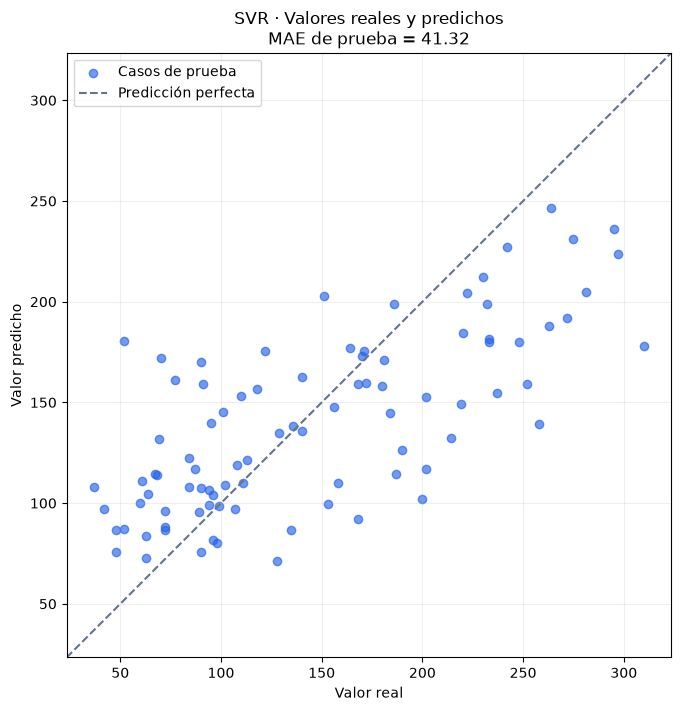

In [20]:
# Graficar los valores reales frente a las predicciones
def grafica_real_vs_pred(y_true, y_pred, algoritmo="SVR"):
    minimo = min(y_true.min(), y_pred.min())
    maximo = max(y_true.max(), y_pred.max())
    margen = (maximo - minimo) * 0.05 or 1
    limites = (minimo - margen, maximo + margen)
    mae_grafica = mean_absolute_error(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.scatter(y_true, y_pred, color="#2563eb", alpha=0.65, label="Casos de prueba")
    ax.plot(limites, limites, "--", color="#64748b", label="Predicción perfecta")
    ax.set(xlim=limites, ylim=limites, xlabel="Valor real", ylabel="Valor predicho")
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{algoritmo} · Valores reales y predichos\nMAE de prueba = {mae_grafica:.2f}")
    ax.grid(alpha=0.2)
    ax.legend()
    plt.show()

grafica_real_vs_pred(y_test, y_pred)

## Gráfico de valores reales frente a predicciones

1. `# Graficar los valores reales frente a las predicciones` describe el propósito de la celda.
2. `def grafica_real_vs_pred(y_true, y_pred, algoritmo="SVR")` define una función que recibe los valores reales y las predicciones. `algoritmo` es el nombre que aparece en el título.
3. `minimo = min(y_true.min(), y_pred.min())` encuentra el menor valor entre ambos conjuntos.
4. `maximo = max(y_true.max(), y_pred.max())` encuentra el mayor valor entre ambos conjuntos.
5. `margen = (maximo - minimo) * 0.05 or 1` deja un margen del 5 % a cada lado. Si todos los valores coinciden, usa un margen de 1.
6. `limites = (minimo - margen, maximo + margen)` prepara los límites que compartirán los dos ejes.
7. `mae_grafica = mean_absolute_error(y_true, y_pred)` calcula el error absoluto medio de los casos graficados.
8. `fig, ax = plt.subplots(...)` crea una figura cuadrada y ajusta el espacio para el título y las etiquetas.
9. `ax.scatter(...)` dibuja un punto por caso. El valor real queda en el eje horizontal y la predicción en el vertical. `alpha=0.65` hace los puntos parcialmente transparentes.
10. `ax.plot(limites, limites, "--", ...)` dibuja la diagonal discontinua donde el valor predicho coincide con el real.
11. `ax.set(...)` aplica los mismos límites a ambos ejes y les pone sus etiquetas.
12. `ax.set_aspect("equal", adjustable="box")` hace que una unidad tenga la misma longitud en ambos ejes.
13. `ax.set_title(...)` muestra el nombre del modelo y el MAE con dos decimales. `\n` coloca el MAE en una segunda línea.
14. `ax.grid(alpha=0.2)` añade una cuadrícula tenue para facilitar la lectura.
15. `ax.legend()` identifica los puntos y la diagonal.
16. `plt.show()` muestra la figura en Jupyter.
17. `grafica_real_vs_pred(y_test, y_pred)` ejecuta la función con los valores reales y predichos de prueba.

Los puntos **por encima de la diagonal** son sobreestimaciones. Los puntos **por debajo** son subestimaciones. La distancia vertical de cada punto a la diagonal representa su error absoluto.

# Diccionario de vocabulario

Los términos están ordenados alfabéticamente. Las definiciones de las variables del dataset provienen de `DESCR`; las demás describen el uso del término en este notebook.

| Término | Definición |
|---|---|
| **age** | Variable del dataset: edad en años (aparece escalada). |
| **bmi** | *Body mass index*: índice de masa corporal. |
| **bp** | *Blood pressure*: presión arterial promedio. |
| **C (SVR)** | Hiperparámetro que controla cuánto se penalizan los errores que superan el margen de tolerancia. Aquí `C=10`. |
| **Centrado en la media** | Restar a cada columna su media para que quede con media cero. |
| **Clase `Pipeline`** | Cadena de pasos que se ejecutan en orden: aquí, estandarizar y luego aplicar el SVR. |
| **`clone`** | Función que crea una copia sin entrenar de un modelo con los mismos hiperparámetros. |
| **Correlación de Pearson** | Medida de la relación lineal entre dos variables, entre -1 y 1. No implica causalidad. |
| **CRISP-DM** | *Cross-Industry Standard Process for Data Mining*: metodología de seis fases: comprensión del negocio, comprensión de los datos, preparación, modelado, evaluación y despliegue. |
| **Dataset** | Conjunto de datos organizado en filas (casos) y columnas (variables). |
| **DataFrame** | Tabla de pandas con filas y columnas etiquetadas. |
| **`DESCR`** | Texto de documentación que acompaña al dataset en scikit-learn. |
| **Desviación estándar** | Medida de cuánto se dispersan los valores respecto a la media. |
| **Diagrama de caja (*boxplot*)** | Gráfico que resume mediana, cuartiles y valores extremos. |
| **Entrenamiento (*train*)** | Subconjunto de datos con el que el modelo aprende. |
| **Escalado / estandarización** | Transformar las variables para que tengan una escala comparable. `StandardScaler` resta la media y divide por la desviación estándar. |
| **Evaluación** | Fase en la que se mide qué tan bien predice el modelo. |
| **`gamma` (SVR)** | Hiperparámetro que controla qué tan local es la influencia de cada punto. Con `"scale"` se calcula automáticamente. |
| **Giro del negocio** | Actividad o ámbito al que se dedica una organización. Aquí: análisis de datos médicos de pacientes con diabetes. |
| **glu (`s6`)** | Nivel de azúcar en sangre. |
| **Hiperparámetro** | Valor de configuración del modelo que se fija antes de entrenar. |
| **Histograma** | Gráfico de barras que muestra con qué frecuencia aparecen los valores de una variable. |
| **Holdout** | División única de los datos en entrenamiento y prueba. Aquí, 80 % y 20 %. |
| **hdl (`s3`)** | Lipoproteínas de alta densidad. |
| **`KFold`** | Validación cruzada que divide los datos en *k* grupos; en cada ronda uno valida y los demás entrenan. |
| **Kernel RBF** | Función de base radial; permite al SVR aprender relaciones no lineales. |
| **ldl (`s2`)** | Lipoproteínas de baja densidad. |
| **Línea base (*baseline*)** | Momento inicial en que se midieron las variables de entrada. |
| **ltg (`s5`)** | Posiblemente el logaritmo del nivel de triglicéridos séricos. |
| **MAE** | *Mean Absolute Error*: promedio de las diferencias absolutas entre valor real y predicho, en las unidades de `target`. |
| **MAPE** | *Mean Absolute Percentage Error*: error absoluto medio expresado como porcentaje del valor real. Falla si el valor real es cero. |
| **Métrica** | Valor numérico que resume el desempeño de un modelo. |
| **Minería de datos** | Proceso de extraer patrones y conocimiento a partir de datos. |
| **Modelo** | Representación matemática que aprende de los datos para hacer predicciones. |
| **Objetivo de minería de datos** | Traducción del objetivo de negocio a una tarea técnica concreta (aquí, regresión). |
| **Outlier (valor atípico)** | Valor muy alejado del resto de los datos. |
| **Predicción** | Valor que estima el modelo para un caso. |
| **Progresión de la enfermedad** | Medida cuantitativa del avance de la diabetes un año después de la línea base; es la variable `target`. |
| **Prueba (*test*)** | Subconjunto reservado para evaluar el modelo al final, sin haberlo usado para entrenar. |
| **`random_state`** | Semilla que hace reproducible una división aleatoria. Aquí, `42`. |
| **Regresión** | Tarea supervisada cuyo objetivo es predecir un valor numérico continuo. |
| **RMSE** | *Root Mean Squared Error*: raíz del error cuadrático medio; penaliza más los errores grandes. |
| **s1 – s6** | Seis mediciones de suero sanguíneo del dataset (ver `tc`, `ldl`, `hdl`, `tch`, `ltg`, `glu`). |
| **Asimetría (*skew*)** | Medida de qué tanto se inclina una distribución hacia un lado. |
| **scikit-learn** | Librería de Python para aprendizaje automático. |
| **sex** | Variable binaria del dataset; su codificación no está documentada. |
| **`StandardScaler`** | Clase de scikit-learn que estandariza cada variable. |
| **SVR** | *Support Vector Regression*: regresión basada en máquinas de vectores de soporte. |
| **Suma de cuadrados** | Suma de los valores elevados al cuadrado. En las variables de entrada de este dataset vale 1 por columna. |
| **Target (variable objetivo)** | Variable que el modelo debe predecir. |
| **tc (`s1`)** | Colesterol sérico total. |
| **tch (`s4`)** | Colesterol total / HDL. |
| **Validación cruzada** | Técnica que evalúa el modelo en varias particiones de los datos para obtener una medida más estable. |
| **Variable de entrada (*feature*)** | Variable que el modelo usa para predecir. Aquí, las 10 primeras columnas. |